<a href="https://colab.research.google.com/github/Israel-San-Agustin/Investigacion-de-operacines-/blob/main/Tarea_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#<font color = "MediumBlue"> CADENAS ABSORVENTES

###<font color = "CornflowerBlue"> Ejercicio 1. La rata en el laberinto

*Una rata comienza en el compartimento $0$ y se desplaza aleatoriamente por los compartimentos adyacentes. Si un compartimento tiene $k$ salidas, cada salida se elige con probabilidad $\frac{1}{k}$.*

*El compartimento $7$ contiene comida y el compartimento $8$ produce una descarga eléctrica. Ambos son estados absorbentes. Se desea estimar mediante simulación la probabilidad de que la rata encuentre la comida antes de recibir una descarga.*

*Donde los estados son*

*   Transitorios: $0,1,2,3,4,5,6.$
*   Absorbentes: $7$ (comida) y $8$ (descarga).
*   Estado inicial: $0$.

Las conexiones entre compartimentos son:
$$
(0,1), (0,2), (1,3), (1,7), (2,3), (2,8),
(3,4), (3,5), (4,6), (4,7), (5,6), (5,8).
$$

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

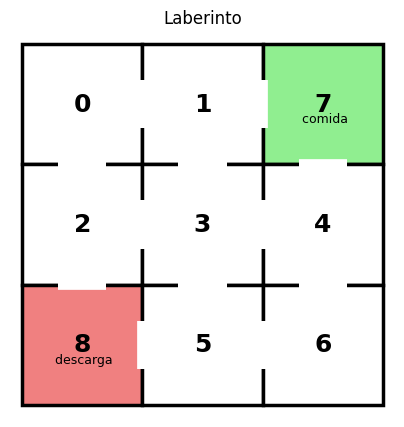

In [61]:
G = nx.Graph()

conexiones = [
    (0, 1), (0, 2),
    (1, 3), (1, 7),
    (2, 3), (2, 8),
    (3, 4), (3, 5),
    (4, 6), (4, 7),
    (5, 6), (5, 8)
]

G.add_edges_from(conexiones)


def dibujar_tablero(G):
    # Cómo está acomodado el laberinto (fila por fila)
    disposicion = [[0, 1, 7],
                   [2, 3, 4],
                   [8, 5, 6]]

    centro = {}                                   # nodo -> centro de su casilla
    fig, ax = plt.subplots(figsize=(5, 5))

    # 1) Dibujar las 9 casillas
    for fila in range(3):
        for col in range(3):
            n = disposicion[fila][col]
            x, y = col, 2 - fila                  # la fila 0 va arriba
            centro[n] = (x + 0.5, y + 0.5)
            color = ("lightgreen" if n == 7 else
                     "lightcoral" if n == 8 else
                     "white")
            ax.add_patch(plt.Rectangle((x, y), 1, 1, fc=color, ec="black", lw=2.5))
            ax.text(x + 0.5, y + 0.5, str(n), ha="center", va="center",
                    fontsize=18, fontweight="bold")

    ax.text(*centro[7], "\n\n comida", ha="center", va="center", fontsize=9)
    ax.text(*centro[8], "\n\n descarga", ha="center", va="center", fontsize=9)

    # 2) Dibujar una puerta por cada arista del tablero
    for u, v in G.edges():
        (xu, yu), (xv, yv) = centro[u], centro[v]
        mx, my = (xu + xv) / 2, (yu + yv) / 2     # punto medio de la pared compartida
        if yu == yv:                              # vecinos en la misma fila, pared vertical
            ax.plot([mx, mx], [my - 0.2, my + 0.2], color="white", lw=7,
                    solid_capstyle="butt", zorder=3)
        else:                                     # vecinos en la misma columna, pared horizontal
            ax.plot([mx - 0.2, mx + 0.2], [my, my], color="white", lw=7,
                    solid_capstyle="butt", zorder=3)

    ax.set_xlim(-0.1, 3.1)
    ax.set_ylim(-0.1, 3.1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Laberinto")
    plt.show()


dibujar_tablero(G)

La función termina cuando se alcanza el compartimento $7$ o el $8$. Devuelve:
*   $7$ si la rata encuentra la comida.
*   $8$ si recibe la descarga.

También devuelve el número de movimientos realizados.

In [62]:
def simular_rata(G, inicio=0):
    actual = inicio
    movimientos = 0

    while actual not in (7, 8):
        vecinos = list(G.neighbors(actual))
        actual = np.random.choice(vecinos)
        movimientos += 1

    return actual, movimientos

In [65]:
N = 100_000

resultados = np.zeros(N, dtype=int)
movimientos = np.zeros(N, dtype=int)

for i in range(N):
    resultados[i], movimientos[i] = simular_rata(G)

comida = np.sum(resultados == 7)
descarga = np.sum(resultados == 8)

prob_comida = comida / N
prob_descarga = descarga / N

print("Simulaciones:", N)
print("Llegó a la comida:", comida)
print("Recibió descarga:", descarga)
print("Probabilidad simulada de comida:", prob_comida)
print("Probabilidad simulada de descarga:", prob_descarga)

Simulaciones: 100000
Llegó a la comida: 50174
Recibió descarga: 49826
Probabilidad simulada de comida: 0.50174
Probabilidad simulada de descarga: 0.49826


*De la solucion analitica coincide en $\frac{1}{2}$ ya que mientras mas simulaciones se va hacercando*

###<font color = "CornflowerBlue"> Ejercicio 2. Serpientes y escaleras

*El juego comienza en la casilla $1$ y termina al alcanzar la casilla $20$, sin retorno. En cada turno se lanza un dado ordinario de seis caras. El movimiento puede activar una escalera o una serpiente, que transporta inmediatamente al jugador a otra casilla.*

*Las conexiones especiales identificadas en el tablero son:*
- Escalera: $3\to11.$
- Serpiente: $13\to4.$
- Escalera: $15\to19.$
- Serpiente: $17\to10.$

*El estado $20$ es absorbente: una vez alcanzado, el juego termina.*

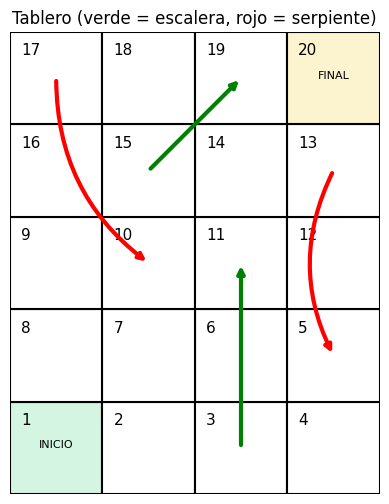

In [78]:
G = nx.DiGraph()

movimientos_especiales = [
    (3, 11),   # escalera
    (13, 5),   # serpiente
    (15, 19),  # escalera
    (17, 10)    # serpiente
]

G.add_nodes_from(range(1, 21))
G.add_edges_from(movimientos_especiales)


# ---------- Dibujo del tablero (4 columnas, serpentina, el 1 abajo a la izquierda) ----------
def centro(n):
    fila, k = divmod(n - 1, 4)                 # fila contada desde abajo
    col = k if fila % 2 == 0 else 3 - k        # las filas impares van de derecha a izquierda
    return col + 0.5, fila + 0.5

def dibujar_tablero():
    fig, ax = plt.subplots(figsize=(5, 6))
    for n in range(1, 21):
        x, y = centro(n)
        color = "#d5f5e3" if n == 1 else "#fcf3cf" if n == 20 else "white"
        ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, fc=color, ec="black", lw=1.5))
        ax.text(x - .38, y + .3, str(n), fontsize=11, va="center")
    for a, b in movimientos_especiales:
        es_escalera = b > a
        ax.annotate("", xy=centro(b), xytext=centro(a),
                    arrowprops=dict(arrowstyle="-|>", lw=3,
                                    color="green" if es_escalera else "red",
                                    connectionstyle="arc3,rad=0" if es_escalera else "arc3,rad=0.25"))
    ax.text(*centro(1), "\n\nINICIO", ha="center", fontsize=8)
    ax.text(*centro(20), "\n\nFINAL", ha="center", fontsize=8)
    ax.set_xlim(0, 4); ax.set_ylim(0, 5)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Tablero (verde = escalera, rojo = serpiente)")
    plt.show()

dibujar_tablero()


*La función `aplicar_movimiento_especial()` recibe la casilla donde cayó el dado. Si existe una conexión dirigida desde esa casilla, devuelve su destino; de lo contrario, conserva la casilla.*

*La casilla 20 no tiene una salida especial y se considera absorbente.*

In [82]:
def aplicar_movimiento_especial(casilla):
    if G.out_degree(casilla) > 0:
        return next(G.successors(casilla))
    return casilla

def simular_partida():
    posicion = 1
    tiradas = 0

    while posicion != 20:
        dado = np.random.randint(1, 7)
        tiradas += 1
        llegada = posicion + dado

        if llegada > 20:
            continue  # Se queda en la misma casilla si sobrepasa 20.

        posicion = aplicar_movimiento_especial(llegada)

    return tiradas




*Repetimos el juego $N$ veces.*

In [83]:
N = 100_000
resultados = np.empty(N, dtype=int)

for i in range(N):
    resultados[i] = simular_partida()

promedio_simulado = np.mean(resultados)
ee = np.std(resultados, ddof=1) / np.sqrt(N)

print("Número de partidas:", N)
print("Promedio simulado de tiradas:", promedio_simulado)
print("Desviación estándar de las tiradas:", np.std(resultados, ddof=1))

Número de partidas: 100000
Promedio simulado de tiradas: 11.28514
Desviación estándar de las tiradas: 6.280674298918588


## <font color = "DeepSkyBlue"> Concucion

las simulaciones se van acercando a la solucion analitica mientras cuando N es cada ves mas gande o mientras mas simulaciones el numero coincidira